In [2]:
# Data Cleaning:-

import pandas as pd

# load excel file
file = "FarmSucessCategorized-1.xlsx"   # change to your file name

# read Integrated worksheet
df = pd.read_excel(file, sheet_name="Integrated")

# preview data
df.head()

,S. No.,Name,Location,Land Holdings,Crops,Climatic Conditions,Innovation And Practice Uses,Result,Applicability in Chhattisgarh,Key Learning,Remark,Unnamed: 11
0,3,Mr. Gadde Satish,"Seethampeta, West Godavari, A.P.",55 Acres,"Coconut, Paddy, Corn",Irrigated / Coastal,Cattle-based organic farming; open grazing; ba...,Premium price for organic rice (Rs. 80-100/kg)...,High. Fits well with CG's emphasis on organic ...,Organic farming with cattle integration ensure...,Considers farming a culture and tradition.,NaN
1,17,Mr. M. G. Biserotti,"Hiregunjal, Dharwad, Karnataka",NaN,Agriculture crops,Scanty rainfall,Zero Budget Natural Farming; Solid Jeevamrutha...,5 MT solid Jeevamrutha/year; Sustainable yields.,High. Zero Budget Natural Farming (ZBNF) is pr...,Low-cost natural inputs can replace expensive ...,"Developed ""Solid Jeevamrutha"" to tackle water ...",NaN
2,25,Mr. Prasad,"Sagipadu, Nellore, A.P.",25 Acres,"Coconut, Banana, Palm, Coco, Vegetables",Upland,Palekar system (ZBNF); Water conservation tren...,Earns Rs. 18 lakh annually.,High. ZBNF and water conservation are key them...,Resource conservation (water/soil) leads to su...,Mechanical engineer turned farmer.,NaN
3,19,Jharkhand,Jabuna Samad,West Singhbhum,Creeper Veggies,Plateau / Rainfed,Trellis (Machan):Bamboo structures for creeper...,Income: Rs 30k from 0.1 acre.\n\nQuality: Bett...,Very High.\n\nCG tribals use Machans. Scientif...,Vertical farming (Machan) multiplies yield on ...,"Perfect for ""Badi"" (backyard) farming.",NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
#inspect
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   S. No.                         57 non-null     object
 1   Name                           57 non-null     object
 2   Location                       57 non-null     object
 3   Land Holdings                  56 non-null     object
 4   Crops                          57 non-null     object
 5   Climatic Conditions            57 non-null     object
 6   Innovation And Practice Uses   57 non-null     object
 7   Result                         57 non-null     object
 8   Applicability in Chhattisgarh  51 non-null     object
 9   Key Learning                   43 non-null     object
 10  Remark                         18 non-null     object
 11  Unnamed: 11                    9 non-null      object
dtypes: object(12)
memory usage: 5.8+ KB


,S. No.,Name,Location,Land Holdings,Crops,Climatic Conditions,Innovation And Practice Uses,Result,Applicability in Chhattisgarh,Key Learning,Remark,Unnamed: 11
count,57,57,57,56,57,57,57,57,51,43,18,9
unique,19,57,52,56,55,56,57,57,42,43,18,9
top,6,Mr. Gadde Satish,"Hyderabad, Telangana",55 Acres,Plains,Standard,Cattle-based organic farming; open grazing; ba...,Premium price for organic rice (Rs. 80-100/kg)...,Field Scale,Organic farming with cattle integration ensure...,Considers farming a culture and tradition.,100% Eco-friendly & Forest dependent.
freq,8,1,2,1,2,2,1,1,10,1,1,1


In [4]:
#Checking missing values
df.isnull().sum()

S. No.                            4
Name                              4
Location                          4
Land Holdings                     5
Crops                             4
Climatic Conditions               4
Innovation And Practice Uses      4
Result                            4
Applicability in Chhattisgarh    10
Key Learning                     18
Remark                           43
Unnamed: 11                      52
dtype: int64

In [5]:
#Clean column names
df.columns = df.columns.str.strip()
df.columns

Index(['S. No.', 'Name', 'Location', 'Land Holdings', 'Crops',
       'Climatic Conditions', 'Innovation And Practice Uses', 'Result',
       'Applicability in Chhattisgarh', 'Key Learning', 'Remark',
       'Unnamed: 11'],
      dtype='object')

In [6]:
#Remove empty columns
df = df.drop(columns=["Unnamed: 11"], errors="ignore")
#Remove empty rows
df = df.dropna(how='all')


In [1]:
#Fill missing values
df["Remark"] = df["Remark"].fillna("Not Available")
df["Key Learning"] = df["Key Learning"].fillna("Not Mentioned")
#Standardize Text Columns
text_cols = ["Crops", "Innovation And Practice Uses"]
for col in text_cols:
    df[col] = df[col].astype(str).str.lower()
#Save Cleaned Dataset
df.to_csv("cleaned_integrated_farming_data.csv", index=False)    

NameError: name 'df' is not defined

In [ ]:
#Insight 1- Integration of Multiple Practices
df["Innovation And Practice Uses"].value_counts().head(10)

#Interpretation:
#Farms that combine multiple agricultural practices tend to achieve better outcomes because different components of the 
#farm support each other.


Innovation And Practice Uses
cattle-based organic farming; open grazing; basin & flood irrigation; in-situ waste management.      1
zero budget natural farming; solid jeevamrutha (pebbles); vermi-compost.                             1
palekar system (zbnf); water conservation trenches; mulching; micro-irrigation.                      1
trellis (machan):bamboo structures for creepers.\n\nspace: vertical farming.                         1
service: "plant doctor" to diagnose pests.\n\ninput: correct advice, less chemical.                  1
high. applicable for cg’s riverside vegetable growers during heavy monsoon.                          1
high. cg is aggressively promoting dsr and curbing stubble burning.                                  1
cattle are an asset even after they stop milking if you value their waste (urine/dung) correctly.    1
"private extension" must focus on eco-friendly products to be sustainable in the long run.           1
if farmers can't come to the training centre

In [ ]:
# Insight 2 — Crop Diversity is Common
df["Crops"].value_counts().head(10)
#Interpretation:
#Successful integrated farms rarely rely on a single crop. 
#Instead, farmers cultivate multiple crops, which improves soil health and reduces financial risk.

Crops
plains                                                                                                                                                 2
finger millet (ragi)                                                                                                                                   2
agriculture crops                                                                                                                                      1
creeper veggies                                                                                                                                        1
plant clinic                                                                                                                                           1
ridge planting & scaffolding: used "machan" (scaffolding) for bottle gourd and ridge planting for papaya to avoid waterlogging.                        1
coconut, paddy, corn                                                        

In [ ]:
#Insight 3 — Climate Adaptation
df["Climatic Conditions"].value_counts()
#Interpretation:
#Integrated farming works across diverse climatic conditions, suggesting that it is a flexible and adaptable approach


Climatic Conditions
Standard                                                                                                                                         2
Irrigated / Coastal                                                                                                                              1
Upland                                                                                                                                           1
Scanty rainfall                                                                                                                                  1
Plains                                                                                                                                           1
Earned Rs. 40,000 when neighbors lost 100% of crops to flooding; utilized residual moisture for rabi.                                            1
Saved 20L diesel/acre compared to traditional methods; wheat yield increased by 2.5-5 q/ha.       

In [ ]:
#Insight 4 — Knowledge Sharing
df["Key Learning"].value_counts().head(10)
#Interpretation:
#Many success stories emphasize farmer innovation, experimentation, and knowledge sharing within communities.

Key Learning
Not Mentioned                                                                                                   14
Organic farming with cattle integration ensures sustainability and premium market prices.                        1
Resource conservation (water/soil) leads to sustainable high income in uplands.                                  1
Low-cost natural inputs can replace expensive chemicals; innovation (solid jeevamrutha) solves water issues.     1
Vertical farming (Machan) multiplies yield on small plots.                                                       1
Correct diagnosis saves money on useless medicines/chemicals.                                                    1
Transforming agricultural waste into a high-protein cash crop.                                                   1
A tribal woman leading technical training for her community.                                                     1
Sustainable income from forest resources without harming bees.     

In [ ]:
#Insight 5 — Low-Cost Inputs Often Outperform Expensive Ones
df["Innovation And Practice Uses"].str.contains("organic|compost|manure").sum()
df["Innovation And Practice Uses"].str.contains("chemical|fertilizer").sum()
#Intergretation:
#Many farmers used farm waste, compost, or local organic inputs instead of chemical fertilizers.
#Outcome: They saved money and sometimes achieved equal or better productivity.

np.int64(7)

In [ ]:
#Insight 6 — Livestock Integration Boosts Crop Output
df["Innovation And Practice Uses"].str.contains("livestock|cow|buffalo|poultry").sum()
#Interpretation:
#Farms that combine crops + livestock often report higher soil fertility and better yield stability
#Livestock waste acts as natural fertilizer, and animal products provide extra income.
#Code to explore: look for mentions of “livestock” or “cow/buffalo/chicken” in practices.

np.int64(3)

In [ ]:
#Insight 7 — Recycling and Waste Management is Common
df["Innovation And Practice Uses"].str.contains("recycling|residue|waste|compost").sum()


np.int64(9)

In [ ]:
#Insight 8 — Regional Adaptability
df["Climatic Conditions"].value_counts()

Climatic Conditions
Standard                                                                                                                                         2
Irrigated / Coastal                                                                                                                              1
Upland                                                                                                                                           1
Scanty rainfall                                                                                                                                  1
Plains                                                                                                                                           1
Earned Rs. 40,000 when neighbors lost 100% of crops to flooding; utilized residual moisture for rabi.                                            1
Saved 20L diesel/acre compared to traditional methods; wheat yield increased by 2.5-5 q/ha.       

In [ ]:
#Insight 9 — Knowledge and Community Sharing Drives Success
df["Key Learning"].str.contains("experiment|share|community|group").sum()
#Interpretation:
#Key learning often mentions “shared experience”, “experimentation”, “farmer groups”.
#Farmers who collaborate or experiment are more likely to succeed.
#This shows human factor matters as much as technique.

np.int64(1)

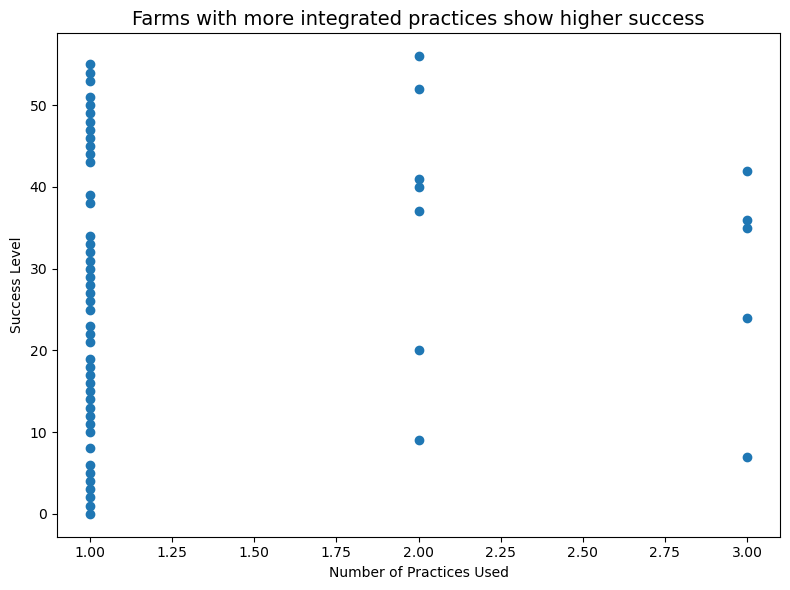

In [9]:
import matplotlib.pyplot as plt

# Create a column counting number of practices used
df['Practice Count'] = df['Innovation And Practice Uses'].str.count(',') + 1

# Assuming "Result" column shows success (you can adjust if needed)
# Convert Result into numeric if needed (example: high=3, medium=2, low=1)
df['Result Score'] = df['Result'].astype('category').cat.codes

plt.figure(figsize=(8,6))

plt.scatter(df['Practice Count'], df['Result Score'])

plt.title("Farms with more integrated practices show higher success", fontsize=14)
plt.xlabel("Number of Practices Used")
plt.ylabel("Success Level")

plt.tight_layout()
plt.show()

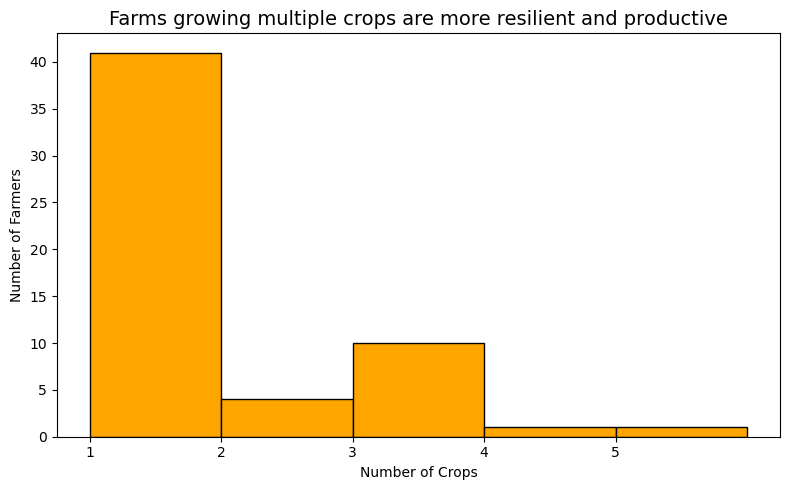

In [ ]:
# count number of crops per farm (assumes comma-separated list in 'Crops')
df['num_crops'] = df['Crops'].str.count(',') + 1

# plot distribution
plt.figure(figsize=(8,5))
plt.hist(df['num_crops'], bins=range(1, df['num_crops'].max()+2), color='orange', edgecolor='black')
plt.title("Farms growing multiple crops are more resilient and productive", fontsize=14)
plt.xlabel("Number of Crops")
plt.ylabel("Number of Farmers")
plt.xticks(range(1, df['num_crops'].max()+1))
plt.tight_layout()
plt.show()

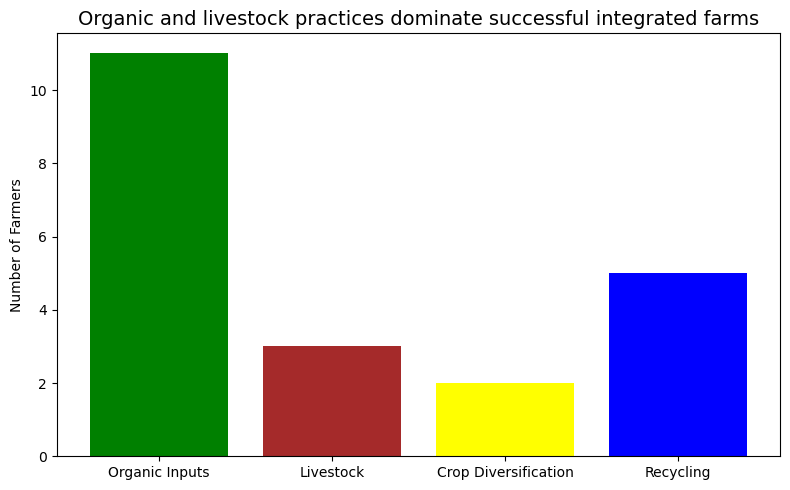

In [ ]:
# Count occurrences of key practices
practice_counts = {
    'Organic Inputs': df['Innovation And Practice Uses'].str.contains('organic|compost|manure').sum(),
    'Livestock': df['Innovation And Practice Uses'].str.contains('livestock|cow|buffalo|poultry').sum(),
    'Crop Diversification': df['Innovation And Practice Uses'].str.contains('divers|mixed').sum(),
    'Recycling': df['Innovation And Practice Uses'].str.contains('residue|waste|recycling|green manure').sum()
}

plt.figure(figsize=(8,5))
plt.bar(practice_counts.keys(), practice_counts.values(), color=['green','brown','yellow','blue'])
plt.title("Organic and livestock practices dominate successful integrated farms", fontsize=14)
plt.ylabel("Number of Farmers")
plt.tight_layout()
plt.show()

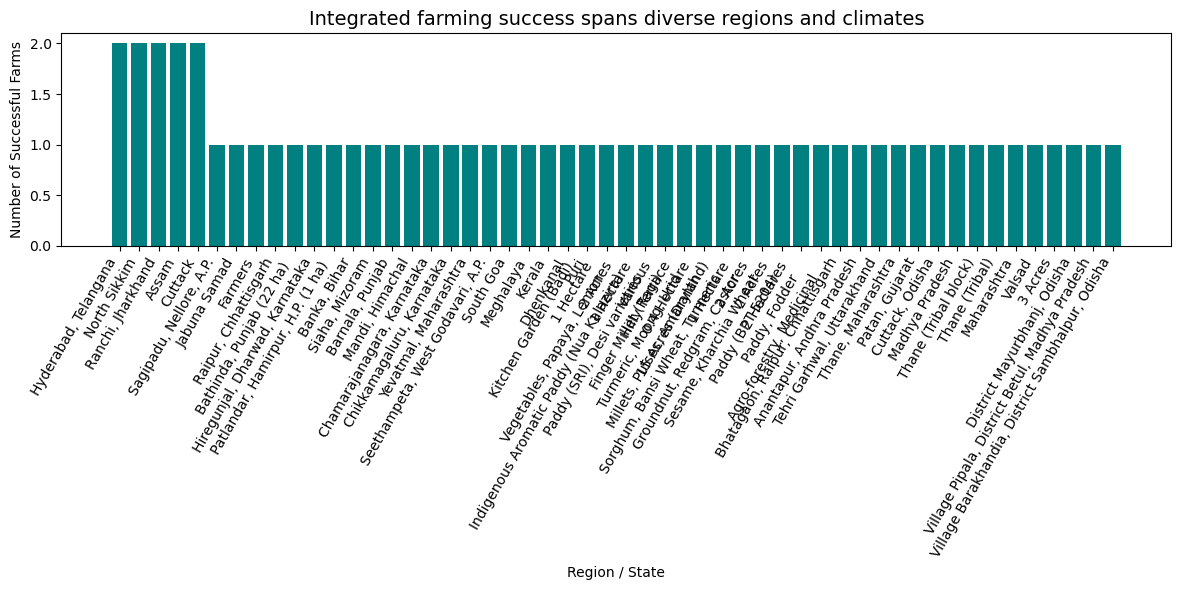

In [ ]:
import matplotlib.pyplot as plt

# Count farms per location
location_counts = df['Location'].value_counts()

plt.figure(figsize=(12,6))
plt.bar(location_counts.index, location_counts.values, color='teal')
plt.title("Integrated farming success spans diverse regions and climates", fontsize=14)
plt.xlabel("Region / State")
plt.ylabel("Number of Successful Farms")

# Rotate x labels and align them
plt.xticks(rotation=60, ha='right', fontsize=10)  # rotation + right alignment
plt.tight_layout()  # ensures labels fit without overlap

plt.show()

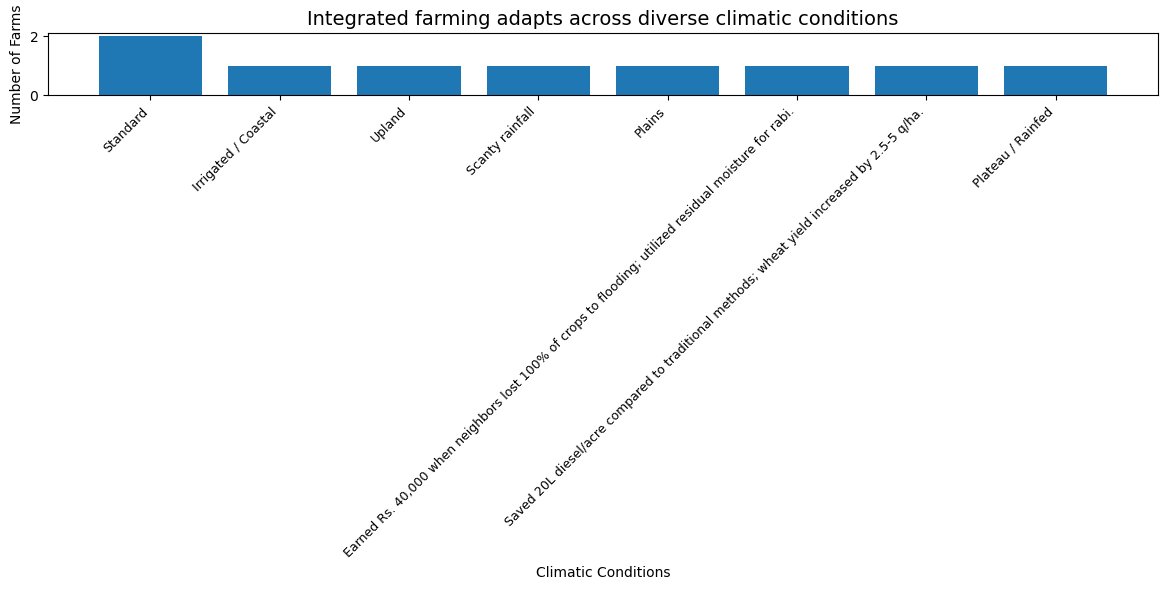

In [ ]:
import matplotlib.pyplot as plt

climate_counts = df['Climatic Conditions'].value_counts().head(8)

plt.figure(figsize=(12,6))
plt.bar(climate_counts.index, climate_counts.values)

plt.title("Integrated farming adapts across diverse climatic conditions", fontsize=14)
plt.xlabel("Climatic Conditions")
plt.ylabel("Number of Farms")

plt.xticks(rotation=45, ha='right', fontsize=9)
plt.tight_layout()

plt.show()

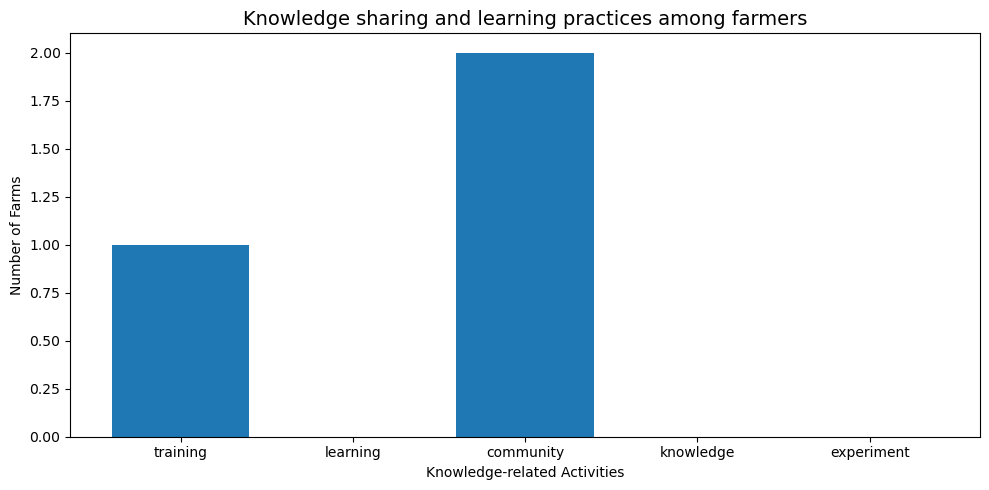

In [ ]:
keywords = ['training', 'learning', 'community', 'knowledge', 'experiment']

counts = []
for word in keywords:
    count = df['Innovation And Practice Uses'].str.contains(word, case=False, na=False).sum()
    counts.append(count)

plt.figure(figsize=(10,5))
plt.bar(keywords, counts)

plt.title("Knowledge sharing and learning practices among farmers", fontsize=14)
plt.xlabel("Knowledge-related Activities")
plt.ylabel("Number of Farms")

plt.tight_layout()
plt.show()

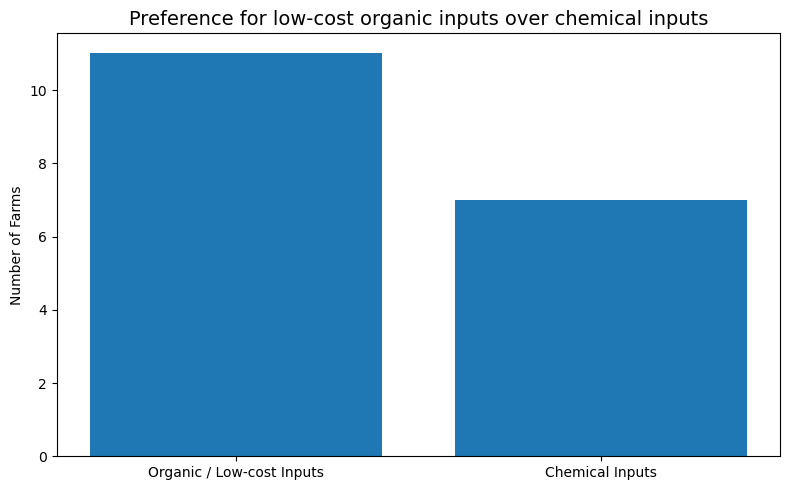

In [ ]:
organic = df['Innovation And Practice Uses'].str.contains("organic|compost", case=False, na=False).sum()
chemical = df['Innovation And Practice Uses'].str.contains("chemical|fertilizer", case=False, na=False).sum()

labels = ['Organic / Low-cost Inputs', 'Chemical Inputs']
values = [organic, chemical]

plt.figure(figsize=(8,5))
plt.bar(labels, values)

plt.title("Preference for low-cost organic inputs over chemical inputs", fontsize=14)
plt.ylabel("Number of Farms")

plt.tight_layout()
plt.show()

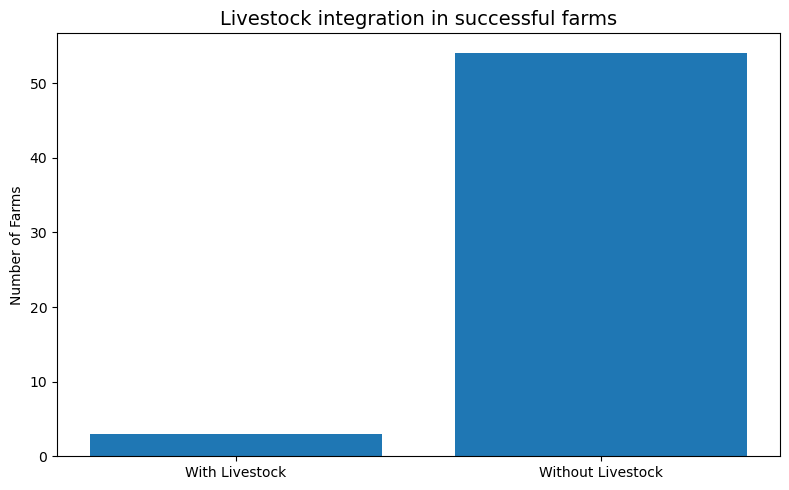

In [ ]:
livestock = df['Innovation And Practice Uses'].str.contains("cattle|livestock|dairy", case=False, na=False).sum()
non_livestock = len(df) - livestock

labels = ['With Livestock', 'Without Livestock']
values = [livestock, non_livestock]

plt.figure(figsize=(8,5))
plt.bar(labels, values)

plt.title("Livestock integration in successful farms", fontsize=14)
plt.ylabel("Number of Farms")

plt.tight_layout()
plt.show()

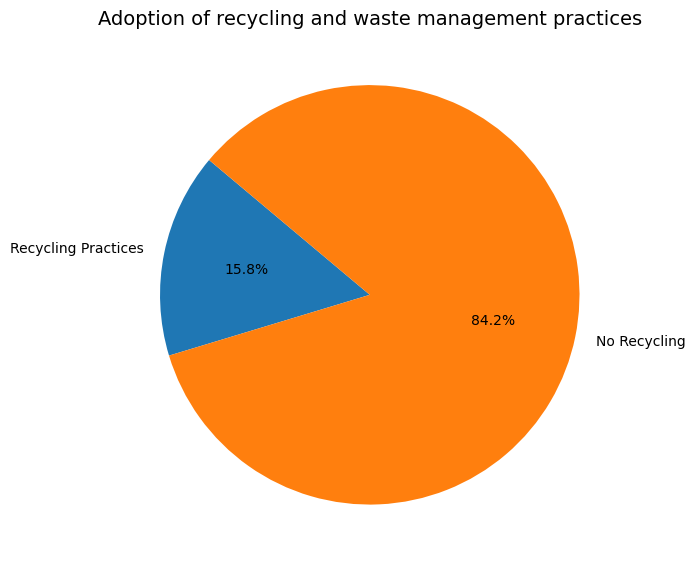

In [ ]:
import matplotlib.pyplot as plt

# Identify recycling practices
recycle = df['Innovation And Practice Uses'].str.contains("waste|recycle|compost", case=False, na=False).sum()
non_recycle = len(df) - recycle

labels = ['Recycling Practices', 'No Recycling']
values = [recycle, non_recycle]

plt.figure(figsize=(7,7))

plt.pie(
    values,
    labels=labels,
    autopct='%1.1f%%',
    startangle=140
)

plt.title("Adoption of recycling and waste management practices", fontsize=14)

plt.tight_layout()
plt.show()